# 🏢 Schindler Elevator Predictive Maintenance
## ML vs Deep Learning — Model Training & Evaluation

**Objective:** Predict whether an elevator unit needs maintenance based on 46 safety inspection checklist items.

**Dataset:** 23,617 inspection records × 46 binary features → `maintenance_needed` (yes/no)

**Models compared:**
1. Logistic Regression (baseline)
2. Random Forest
3. Gradient Boosting
4. XGBoost
5. Deep Neural Network (Keras)

---
## 1. Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import pickle
import os
import json
from datetime import datetime

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    accuracy_score, f1_score, roc_curve, ConfusionMatrixDisplay,
    precision_recall_curve
)
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
)
from sklearn.linear_model import LogisticRegression

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print('XGBoost not installed. Run: pip install xgboost')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f'TensorFlow: {tf.__version__}')
print(f'Sklearn ready | XGBoost: {XGBOOST_AVAILABLE}')

TensorFlow: 2.19.0
Sklearn ready | XGBoost: True


---
## 2. Load & Explore Data

In [7]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

file_name = list(uploaded.keys())[0]
df_raw = pd.read_excel(file_name)

print(f"Shape: {df_raw.shape}")
print(df_raw["maintenance_needed"].value_counts())
df_raw.head(3)

Saving maintenance_dataset.xlsx to maintenance_dataset.xlsx
Shape: (23617, 47)
maintenance_needed
yes    13203
no     10414
Name: count, dtype: int64


,"1.Safe access to equipment/machine room?(illumination, protected access ways) هل هناك وصول آمن إلى المعدات والآلات؟ (الإضاءة ، طرق الوصول المحمية)","2.Is the area free of likely hazardous substances? (eg. asbestos, faeces, vermin, mobile phone masts) هل المنطقة خالية من المواد الخطرة المحتملة؟ (على سبيل المثال ، الأسبتوس والبراز والحشرات وأبراج الهاتف المحمول)",3.Are barriers available for both ends of the equipment?هل توجد حواجز لحماية عمليات الإنزال؟,4.Are there division screens fitted between adjacent units at the end stations? هل يوجد حاجز تقسيم بين المصاعد المتجاورة؟,"5.Are hazards associated with working at height adequately protected? (eg. Ladders, trapdoors) هل الأخطار المرتبطة بالعمل على ارتفاعات محمية بشكل كاف؟ (على سبيل المثال ، السلالم والأبواب الجانبية)",6.Is the controller lockable and capable of being opened without causing any obstructions?هل وحدة التحكم قابلة للقفل ويمكن فتحها دون التسبب في أي عوائق؟,7.ELV/Is the moving machinery/working area adequately guarded?هل الأجزاء الميكانيكية المتحركة محمية بشكل كافٍ؟,8.Is there a barrier to demarcate the controller working area?هل يوجد عائق لترسيم منطقة عمل وحدة التحكم؟,9.Are the rubber mats located at the front of the controllers هل السجادة المطاطية متاحة للعمل على وحدة التحكم؟,10.Are main electrical circuits adequately guarded and signed accordingly? هل الدوائر الكهربائية الرئيسية محمية وموقعة على النحو المناسب؟,11.Is the car top/shaft/area adequately lit? هل المنطقة أعلى المصعد مضاءة بشكل كافٍ؟,"12.Is there a compliant cartop control fitted (stop, inspection/normal and is there a stop switch within 1 m of the landing? هل هناك أداة تحكم في العربة متوافقة (توقف ، فحص / عادي وهل يوجد مفتاح إيقاف على بعد متر واحد من الهبوط؟","13.Can the safety circuit be verified? (door landing door locks & car-top, controller) هل يمكن التحقق من دائرة الأمان؟ (أقفال باب هبوط الباب وسطح عربة المصعد ، وحدة تحكم)","14.Is there safe access to the car top? (cartop handrails fitted, no significant trip hazards) هل هناك وصول آمن إلى أعلى عربة المصعد؟ (تم تركيب الدرابزين الكارتوب ، ولا توجد مخاطر تعثر كبيرة)",15.Are the electrical circuits adequately guarded? هل الدوائر الكهربائية محمية بشكل كافٍ؟,16.Are there any low headroom hazards? Are these controlled and signages available? هل هناك أي مخاطر منخفضة الارتفاع؟ هل هذه الإشارات الخاضعة للرقابة متوفرة؟,"17.If there are other lifts in the shaft, are they separated by a min of 500mm or have division screens? إذا كانت هناك مصاعد أخرى في البئر ، فهل يتم فصلها بمقدار 500 مم على الأقل أم بها حواجز تقسيم؟",18.Are there barriers available to demarcate/protect the working area on the landings? هل توجد حواجز لتحديد منطقة العمل على الإنزال؟,19.Is the shaft / pit adequately lit? هل البير / الحفرة مضاءة بشكل كافٍ؟,20.Is a 750mm car apron fitted?هل ستارة المصعد 750 مم مناسبة؟,21.Is there a suitable ladder available to access the pit? هل يوجد سلم مناسب متاح للوصول إلى الحفرة؟,22.Is there a stop switch located within 750 mm horizontally to the landing? هل يوجد مفتاح إيقاف يقع في نطاق 750 مم أفقيًا حتى الهبوط؟,"23.If a deep pit (>1800mm), is the ladder access located close to the landing? إذا كانت حفرة عميقة (> 1800 مم) ، فهل يقع مدخل السلم بالقرب من الهبوط؟","24.If the pit is (>1600mm) deep, is there a second stop switch accessible from the pit floor? إذا كان عمق الحفرة (> 1600 مم) ، فهل هناك مفتاح إيقاف ثان يمكن الوصول إليه من أرضية الحفرة؟",25.Are there divisions screen fitted between adjacent lifts? هل يوجد حاجز تقسيم بين المصاعد المتجاورة؟,26.Is the lift pit clear of any significant water levels? هل حفرة الرفع خالية من أي مستويات كبيرة من المياه؟,27.Is there a counterweight screen? هل هناك حاجز حماية للموازنة؟,"28.Is the pit clear of any trash, oil spill? هل الحفرة خالية من أي قمامة ، تسرب زيت؟",29.If the pit is shallow are control measures available and signage displayed? إذا كانت الحفرة ضحلة ، فهل يتم عرض إجراءات التحكم؟,"30.If hydraulic, is there a pit prop available for use? إذا كانت هيدروليكية ، فهل هناك دعامة حفرة متاحة للاستخدام؟",31.Can the pit 

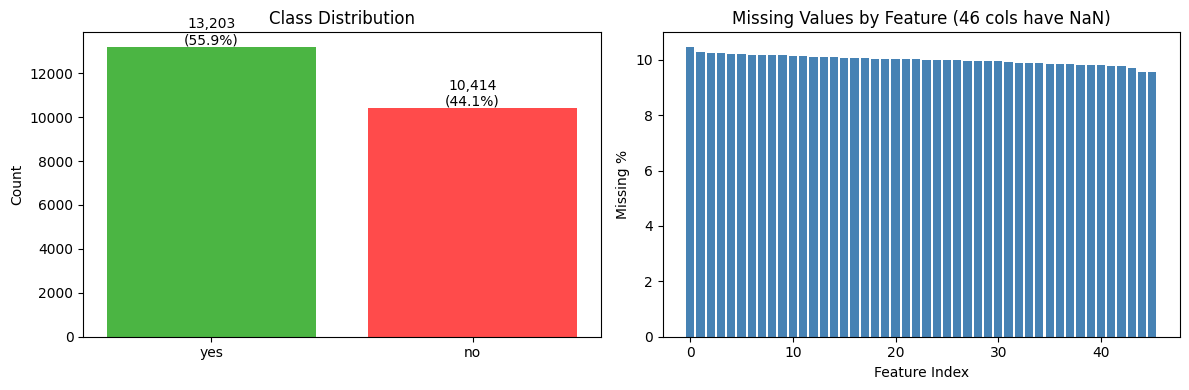

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = df_raw['maintenance_needed'].value_counts()
colors = ['#4BB543', '#FF4B4B']

axes[0].bar(counts.index, counts.values, color=colors)
axes[0].set_title('Class Distribution')
axes[0].set_ylabel('Count')
for i, (label, val) in enumerate(counts.items()):
    axes[0].text(i, val + 100, f'{val:,}\n({val/len(df_raw)*100:.1f}%)', ha='center')

missing_pct = (df_raw.isnull().sum() / len(df_raw) * 100)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)
axes[1].bar(range(len(missing_pct)), missing_pct.values, color='steelblue')
axes[1].set_title(f'Missing Values by Feature ({len(missing_pct)} cols have NaN)')
axes[1].set_xlabel('Feature Index')
axes[1].set_ylabel('Missing %')

plt.tight_layout()
plt.show()

---
## 3. Data Preprocessing

In [9]:
df = df_raw.copy()

# Encode target
df['maintenance_needed'] = df['maintenance_needed'].str.strip().str.lower()
y = (df['maintenance_needed'] == 'yes').astype(int)
print(f'Target: 1=needs maintenance ({y.sum():,}), 0=ok ({(y==0).sum():,})')

# Feature columns
feature_cols = [c for c in df.columns if c != 'maintenance_needed']

# Encode yes/no/nan
def encode_yesno(val):
    v = str(val).strip().lower()
    if v in ('yes', '1', '1.0', 'true'): return 1.0
    if v in ('no', '0', '0.0', 'false'): return 0.0
    return np.nan

X_enc = df[feature_cols].applymap(encode_yesno)

imputer = SimpleImputer(strategy='most_frequent')
X_imputed = pd.DataFrame(imputer.fit_transform(X_enc), columns=feature_cols)

# ── Feature Engineering ──
X_imputed['missing_count'] = X_enc.isnull().sum(axis=1).values
X_imputed['risk_density']  = (X_imputed[feature_cols] == 0).sum(axis=1)
X_imputed['safety_score']  = X_imputed[feature_cols].sum(axis=1) / len(feature_cols)

print(f'Feature matrix (with engineered features): {X_imputed.shape}')
print(f'Any remaining NaN: {X_imputed.isnull().sum().sum()}')
print(' Feature Engineering done: missing_count, risk_density, safety_score')

Target: 1=needs maintenance (13,203), 0=ok (10,414)
Feature matrix (with engineered features): (23617, 49)
Any remaining NaN: 0
 Feature Engineering done: missing_count, risk_density, safety_score


In [10]:
feature_cols_final = list(X_imputed.columns)
print(f'Final feature count: {len(feature_cols_final)} (original {len(feature_cols)} + 3 engineered)')

# Train/Val/Test split: 60/20/20
X_temp, X_test, y_temp, y_test = train_test_split(
    X_imputed, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=SEED, stratify=y_temp
)

print(f'Train: {X_train.shape[0]:,} | Val: {X_val.shape[0]:,} | Test: {X_test.shape[0]:,}')

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

feature_cols = feature_cols_final

Final feature count: 49 (original 46 + 3 engineered)
Train: 14,169 | Val: 4,724 | Test: 4,724


---
## 4. Machine Learning Models

In [11]:
results = {}

def evaluate(name, y_true, y_pred, y_prob=None):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob) if y_prob is not None else None
    results[name] = {'Accuracy': acc, 'F1': f1, 'AUC-ROC': auc}
    print(f'\n=== {name} ===')
    print(f'  Accuracy: {acc:.4f} | F1: {f1:.4f}' + (f' | AUC: {auc:.4f}' if auc else ''))
    print(classification_report(y_true, y_pred, target_names=['OK', 'Needs Maintenance']))

In [12]:
# 4.1 Logistic Regression
print('Training Logistic Regression...')
lr = LogisticRegression(max_iter=500, random_state=SEED)
lr.fit(X_train_sc, y_train)
evaluate('Logistic Regression', y_test, lr.predict(X_test_sc), lr.predict_proba(X_test_sc)[:,1])

Training Logistic Regression...

=== Logistic Regression ===
  Accuracy: 0.7405 | F1: 0.7732 | AUC: 0.8373
                   precision    recall  f1-score   support

               OK       0.72      0.68      0.70      2083
Needs Maintenance       0.76      0.79      0.77      2641

         accuracy                           0.74      4724
        macro avg       0.74      0.73      0.73      4724
     weighted avg       0.74      0.74      0.74      4724



In [13]:
# 4.2 Random Forest
from sklearn.model_selection import RandomizedSearchCV

print(' Tuning Random Forest (RandomizedSearchCV, 20 iterations)...')

rf_grid = {
    'n_estimators':    [100, 200, 300, 500],
    'max_depth':       [6, 10, 12, 16, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf':  [1, 2, 5],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=SEED, n_jobs=-1),
    rf_grid,
    n_iter=20,
    scoring='roc_auc',
    cv=3,
    verbose=1,
    n_jobs=-1,
    random_state=SEED
)
rf_search.fit(X_train, y_train)
rf = rf_search.best_estimator_
print(f' Best RF params: {rf_search.best_params_}')

evaluate('Random Forest', y_test, rf.predict(X_test), rf.predict_proba(X_test)[:,1])

 Tuning Random Forest (RandomizedSearchCV, 20 iterations)...
Fitting 3 folds for each of 20 candidates, totalling 60 fits
 Best RF params: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': None}

=== Random Forest ===
  Accuracy: 0.7170 | F1: 0.7581 | AUC: 0.8040
                   precision    recall  f1-score   support

               OK       0.70      0.62      0.66      2083
Needs Maintenance       0.73      0.79      0.76      2641

         accuracy                           0.72      4724
        macro avg       0.71      0.71      0.71      4724
     weighted avg       0.72      0.72      0.71      4724



In [14]:
# 4.3 Gradient Boosting
print('Training Gradient Boosting...')
gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                                 max_depth=5, random_state=SEED)
gb.fit(X_train, y_train)
evaluate('Gradient Boosting', y_test, gb.predict(X_test), gb.predict_proba(X_test)[:,1])

Training Gradient Boosting...

=== Gradient Boosting ===
  Accuracy: 0.7381 | F1: 0.7721 | AUC: 0.8274
                   precision    recall  f1-score   support

               OK       0.72      0.67      0.69      2083
Needs Maintenance       0.75      0.79      0.77      2641

         accuracy                           0.74      4724
        macro avg       0.74      0.73      0.73      4724
     weighted avg       0.74      0.74      0.74      4724



In [15]:
# 4.4 XGBoost — with Hyperparameter Tuning
if XGBOOST_AVAILABLE:
    print(' Tuning XGBoost (RandomizedSearchCV, 15 iterations)...')

    xgb_grid = {
        'n_estimators':  [200, 300, 500],
        'max_depth':     [4, 6, 8],
        'learning_rate': [0.01, 0.05, 0.1],
        'subsample':     [0.7, 0.8, 1.0],
        'colsample_bytree': [0.7, 0.8, 1.0],
    }

    xgb_search = RandomizedSearchCV(
        XGBClassifier(eval_metric='logloss', random_state=SEED, n_jobs=-1),
        xgb_grid,
        n_iter=15,
        scoring='roc_auc',
        cv=3,
        verbose=1,
        n_jobs=-1,
        random_state=SEED
    )
    xgb_search.fit(X_train, y_train)
    xgb_model = xgb_search.best_estimator_
    print(f' Best XGB params: {xgb_search.best_params_}')

    evaluate('XGBoost', y_test, xgb_model.predict(X_test), xgb_model.predict_proba(X_test)[:,1])
else:
    print('XGBoost not available, skipping.')
    xgb_model = None

 Tuning XGBoost (RandomizedSearchCV, 15 iterations)...
Fitting 3 folds for each of 15 candidates, totalling 45 fits
 Best XGB params: {'subsample': 1.0, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.8}

=== XGBoost ===
  Accuracy: 0.7392 | F1: 0.7726 | AUC: 0.8306
                   precision    recall  f1-score   support

               OK       0.72      0.67      0.69      2083
Needs Maintenance       0.75      0.79      0.77      2641

         accuracy                           0.74      4724
        macro avg       0.74      0.73      0.73      4724
     weighted avg       0.74      0.74      0.74      4724



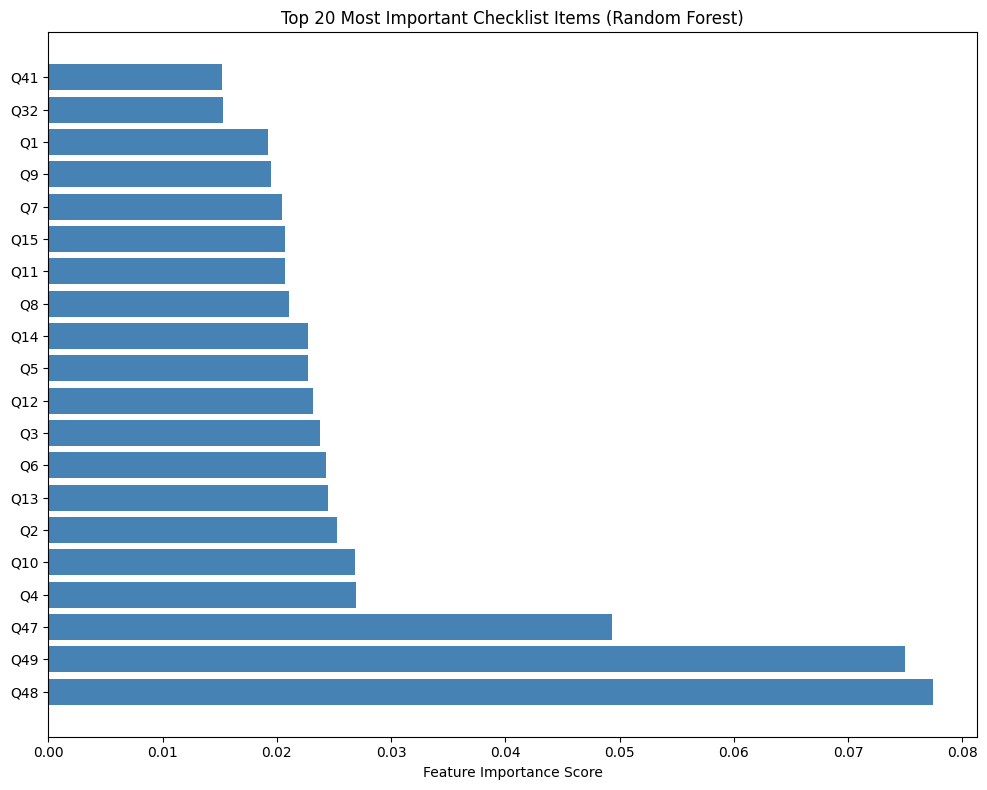


Top 5 Most Predictive Checklist Items:
1. [0.0774] risk_density
2. [0.0750] safety_score
3. [0.0494] missing_count
4. [0.0269] 4.Are there division screens fitted between adjacent units at the end stations? 
5. [0.0268] 10.Are main electrical circuits adequately guarded and signed accordingly? هل ال


In [16]:
# Feature Importance — Random Forest
importances = pd.Series(rf.feature_importances_, index=feature_cols)
top20 = importances.nlargest(20)

short_labels = [str(i+1) + '. ' + label[:40] + '...' if len(label) > 40 else str(i+1) + '. ' + label
                for i, label in enumerate(top20.index)]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(range(len(top20)), top20.values, color='steelblue')
ax.set_yticks(range(len(top20)))
ax.set_yticklabels([f'Q{list(feature_cols).index(c)+1}' for c in top20.index])
ax.set_title('Top 20 Most Important Checklist Items (Random Forest)')
ax.set_xlabel('Feature Importance Score')
plt.tight_layout()
plt.show()

print('\nTop 5 Most Predictive Checklist Items:')
for i, (col, imp) in enumerate(top20.head(5).items(), 1):
    print(f'{i}. [{imp:.4f}] {col[:80]}')

---
## 5. Deep Learning Neural Network

In [17]:
def build_nn(input_dim, dropout_rate=0.3):
    inp = keras.Input(shape=(input_dim,))
    x = layers.Dense(256, activation='relu')(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(dropout_rate / 2)(x)
    x = layers.Dense(32, activation='relu')(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    model = keras.Model(inp, out)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy', keras.metrics.AUC(name='auc')]
    )
    return model

nn_model = build_nn(X_train_sc.shape[1])
nn_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 49)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        12,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,601 (225.00 KB)

 Trainable params: 56,833 (222.00 KB)

 Non-trainable params: 768 (3.00 KB)

In [18]:
cb_list = [
    callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=10,
                            restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5,
                                min_lr=1e-6, verbose=1),
    callbacks.ModelCheckpoint('best_nn_binary.keras', monitor='val_auc',
                               mode='max', save_best_only=True, verbose=0)
]

history = nn_model.fit(
    X_train_sc, y_train,
    validation_data=(X_val_sc, y_val),
    epochs=80,
    batch_size=256,
    callbacks=cb_list,
    verbose=1
)

Epoch 1/80
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.6689 - auc: 0.7271 - loss: 0.6119 - val_accuracy: 0.7314 - val_auc: 0.8127 - val_loss: 0.5709 - learning_rate: 0.0010
Epoch 2/80
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.7294 - auc: 0.8105 - loss: 0.5213 - val_accuracy: 0.7367 - val_auc: 0.8196 - val_loss: 0.5347 - learning_rate: 0.0010
Epoch 3/80
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7396 - auc: 0.8239 - loss: 0.5039 - val_accuracy: 0.7403 - val_auc: 0.8210 - val_loss: 0.5119 - learning_rate: 0.0010
Epoch 4/80
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7521 - auc: 0.8340 - loss: 0.4897 - val_accuracy: 0.7413 - val_auc: 0.8233 - val_loss: 0.4994 - learning_rate: 0.0010
Epoch 5/80
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7531 - auc: 0.8397 - loss: 0.4820 - val_accuracy: 0.7407 - val_auc: 0.8239 - val_loss: 0.4957 - learning_rate: 0.0010
Epoch 6/80
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7523 - auc: 0.8404 -

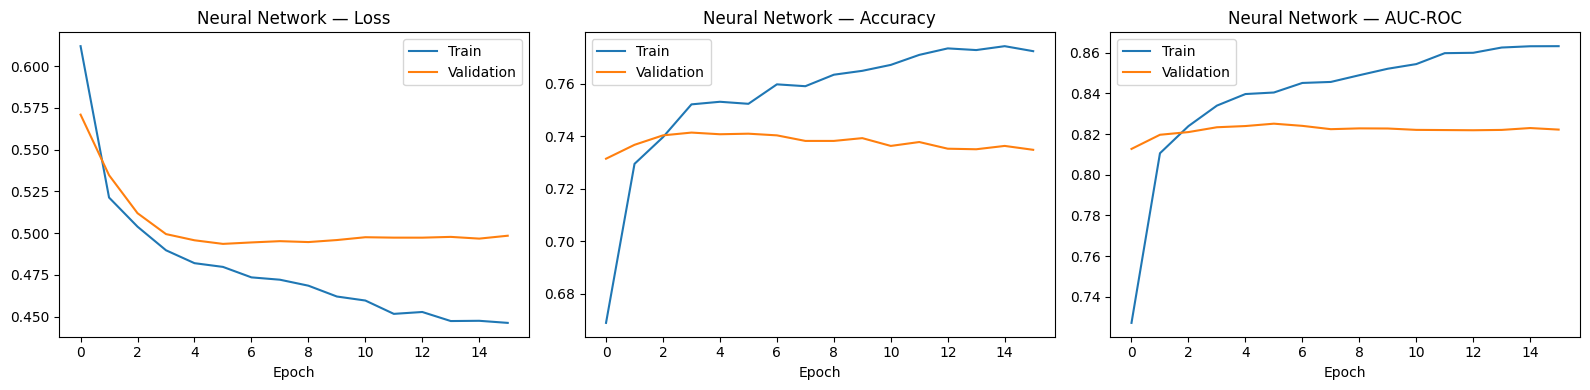

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric, title in zip(axes, ['loss', 'accuracy', 'auc'], ['Loss', 'Accuracy', 'AUC-ROC']):
    ax.plot(history.history[metric], label='Train')
    ax.plot(history.history[f'val_{metric}'], label='Validation')
    ax.set_title(f'Neural Network — {title}')
    ax.set_xlabel('Epoch')
    ax.legend()
plt.tight_layout()
plt.show()

In [20]:
nn_prob = nn_model.predict(X_test_sc, verbose=0).ravel()
nn_pred = (nn_prob >= 0.5).astype(int)
evaluate('Neural Network', y_test, nn_pred, nn_prob)


=== Neural Network ===
  Accuracy: 0.7407 | F1: 0.7514 | AUC: 0.8290
                   precision    recall  f1-score   support

               OK       0.68      0.79      0.73      2083
Needs Maintenance       0.81      0.70      0.75      2641

         accuracy                           0.74      4724
        macro avg       0.74      0.75      0.74      4724
     weighted avg       0.75      0.74      0.74      4724



---
## 6. Model Comparison & Winner Selection


 🏆 FINAL MODEL LEADERBOARD (Smart Multi-Metric Ranking)
                     Accuracy      F1  AUC-ROC    Score
Logistic Regression    0.7405  0.7732   0.8373  0.79871
XGBoost                0.7392  0.7726   0.8306  0.79492
Gradient Boosting      0.7381  0.7721   0.8274  0.79295
Neural Network         0.7407  0.7514   0.8290  0.78806
Random Forest          0.7170  0.7581   0.8040  0.77283


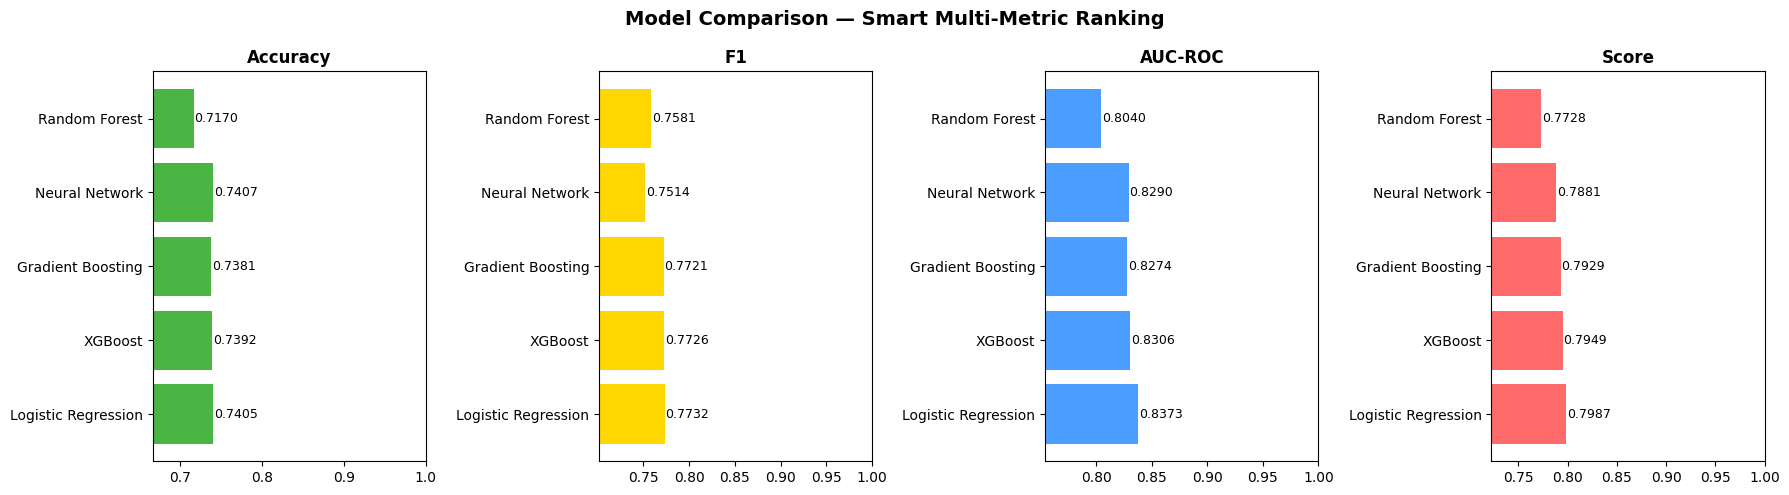


 ✅ WINNER (by Smart Score): Logistic Regression
   AUC=0.8373 | F1=0.7732 | Score=0.7987


In [21]:
results_df = pd.DataFrame(results).T.round(4)

# Smart Multi-Metric Score — prevents winning by AUC alone with weak F1
results_df['Score'] = (
    0.5 * results_df['AUC-ROC'].fillna(0) +
    0.3 * results_df['F1'].fillna(0) +
    0.2 * results_df['Accuracy'].fillna(0)
)
results_df = results_df.sort_values('Score', ascending=False)

print('\n 🏆 FINAL MODEL LEADERBOARD (Smart Multi-Metric Ranking)')
print('=' * 65)
print(results_df[['Accuracy','F1','AUC-ROC','Score']].to_string())
print('=' * 65)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col, color in zip(axes,
                           ['Accuracy', 'F1', 'AUC-ROC', 'Score'],
                           ['#4BB543', '#FFD700', '#4B9EFF', '#FF6B6B']):
    vals = results_df[col].dropna()
    ax.barh(vals.index, vals.values, color=color)
    ax.set_xlim(max(0, vals.min() - 0.05), 1.0)
    ax.set_title(col, fontweight='bold')
    for i, v in enumerate(vals.values):
        ax.text(v + 0.001, i, f'{v:.4f}', va='center', fontsize=9)
plt.suptitle('Model Comparison — Smart Multi-Metric Ranking', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

winner_name = results_df['Score'].idxmax()
print(f'\n ✅ WINNER (by Smart Score): {winner_name}')
print(f'   AUC={results_df.loc[winner_name,"AUC-ROC"]:.4f} | F1={results_df.loc[winner_name,"F1"]:.4f} | Score={results_df.loc[winner_name,"Score"]:.4f}')

---
## 7.  VOTING ENSEMBLE — RF + GB + XGB + NN

In [30]:
print("Building Voting Ensemble...")

import numpy as np

# =========================================================
# 1. VALIDATE MODELS
# =========================================================
def safe_estimator(model, name):
    if model is None:
        print(f"[SKIP] {name} is None")
        return None
    if isinstance(model, dict):
        raise ValueError(f"{name} is a DICT — loaded incorrectly!")
    print(f"[OK] {name}")
    return model


rf = safe_estimator(rf, "Random Forest")
gb = safe_estimator(gb, "Gradient Boosting")
xgb_model = safe_estimator(xgb_model, "XGBoost") if XGBOOST_AVAILABLE else None


# =========================================================
# 2. COLLECT PREDICTIONS (SOFT VOTING)
# =========================================================
prob_list = []

if rf is not None:
    prob_list.append(rf.predict_proba(X_test)[:, 1])
    print("[✓] RF probabilities collected")

if gb is not None:
    prob_list.append(gb.predict_proba(X_test)[:, 1])
    print("[✓] GB probabilities collected")

if xgb_model is not None:
    prob_list.append(xgb_model.predict_proba(X_test)[:, 1])
    print("[✓] XGB probabilities collected")

if nn_model is not None:
    nn_probs = nn_model.predict(scaler.transform(X_test), verbose=0).ravel()
    prob_list.append(nn_probs)
    print("[✓] NN probabilities collected")


# =========================================================
# 3. AVERAGE (SOFT VOTING)
# =========================================================
v_prob = np.mean(prob_list, axis=0)
v_pred = (v_prob >= 0.5).astype(int)


# =========================================================
# 4. EVALUATION
# =========================================================
evaluate("Voting Ensemble (Manual Soft)", y_test, v_pred, v_prob)

print(f"\nVoting Ensemble completed successfully! ({len(prob_list)} models combined)")


# =========================================================
# 5. REUSABLE FUNCTION (FOR APP / THRESHOLD TUNING)
# =========================================================
def voting_predict_proba(X, X_scaled=None):
    """
    Manual soft voting ensemble prediction function.
    Can be reused in Streamlit app or deployment.
    """

    probs = []

    if rf is not None:
        probs.append(rf.predict_proba(X)[:, 1])

    if gb is not None:
        probs.append(gb.predict_proba(X)[:, 1])

    if xgb_model is not None:
        probs.append(xgb_model.predict_proba(X)[:, 1])

    if nn_model is not None:
        X_input = X_scaled if X_scaled is not None else scaler.transform(X)
        probs.append(nn_model.predict(X_input, verbose=0).ravel())

    return np.mean(probs, axis=0)


print("voting_predict_proba() is ready for production use ")

Building Voting Ensemble...
[OK] Random Forest
[OK] Gradient Boosting
[OK] XGBoost
[✓] RF probabilities collected
[✓] GB probabilities collected
[✓] XGB probabilities collected
[✓] NN probabilities collected

=== Voting Ensemble (Manual Soft) ===
  Accuracy: 0.7449 | F1: 0.7738 | AUC: 0.8313
                   precision    recall  f1-score   support

               OK       0.72      0.70      0.71      2083
Needs Maintenance       0.77      0.78      0.77      2641

         accuracy                           0.74      4724
        macro avg       0.74      0.74      0.74      4724
     weighted avg       0.74      0.74      0.74      4724


Voting Ensemble completed successfully! (4 models combined)
voting_predict_proba() is ready for production use 


Optimizing decision threshold on validation set...
Best threshold: 0.3674  (default was 0.5)
   Max F1 on val:  0.7683

=== Voting Ensemble (threshold=0.367) ===
  Accuracy: 0.7085 | F1: 0.7751 | AUC: 0.8313
                   precision    recall  f1-score   support

               OK       0.78      0.47      0.59      2083
Needs Maintenance       0.68      0.90      0.78      2641

         accuracy                           0.71      4724
        macro avg       0.73      0.68      0.68      4724
     weighted avg       0.73      0.71      0.69      4724



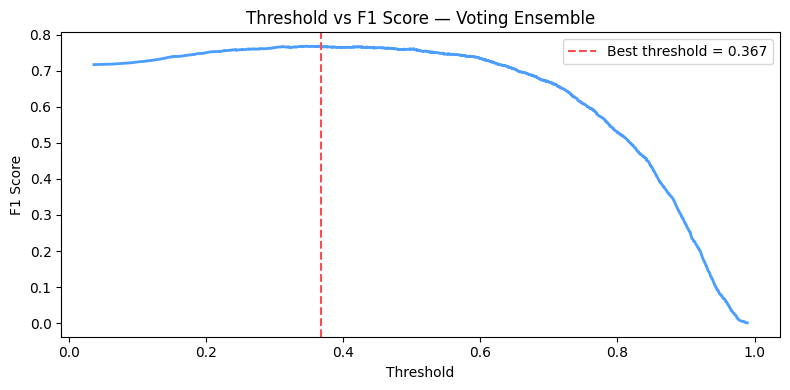

In [32]:
# =========================================================
# THRESHOLD OPTIMIZATION — Best F1 threshold automatically
print('Optimizing decision threshold on validation set...')

val_prob_voting = voting_predict_proba(X_val, X_val_sc)

precision, recall, thresholds = precision_recall_curve(y_val, val_prob_voting)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-9)

best_idx       = np.argmax(f1_scores[:-1])
best_threshold = float(thresholds[best_idx])

print(f'Best threshold: {best_threshold:.4f}  (default was 0.5)')
print(f'   Max F1 on val:  {f1_scores[best_idx]:.4f}')

v_prob     = voting_predict_proba(X_test, X_test_sc)
v_pred_opt = (v_prob >= best_threshold).astype(int)
v_pred     = (v_prob >= 0.5).astype(int)

evaluate(f'Voting Ensemble (threshold={best_threshold:.3f})', y_test, v_pred_opt, v_prob)

plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores[:-1], color='#4B9EFF', linewidth=2)
plt.axvline(best_threshold, color='#FF4B4B', linestyle='--',
            label=f'Best threshold = {best_threshold:.3f}')
plt.xlabel('Threshold'); plt.ylabel('F1 Score')
plt.title('Threshold vs F1 Score — Voting Ensemble')
plt.legend(); plt.tight_layout(); plt.show()

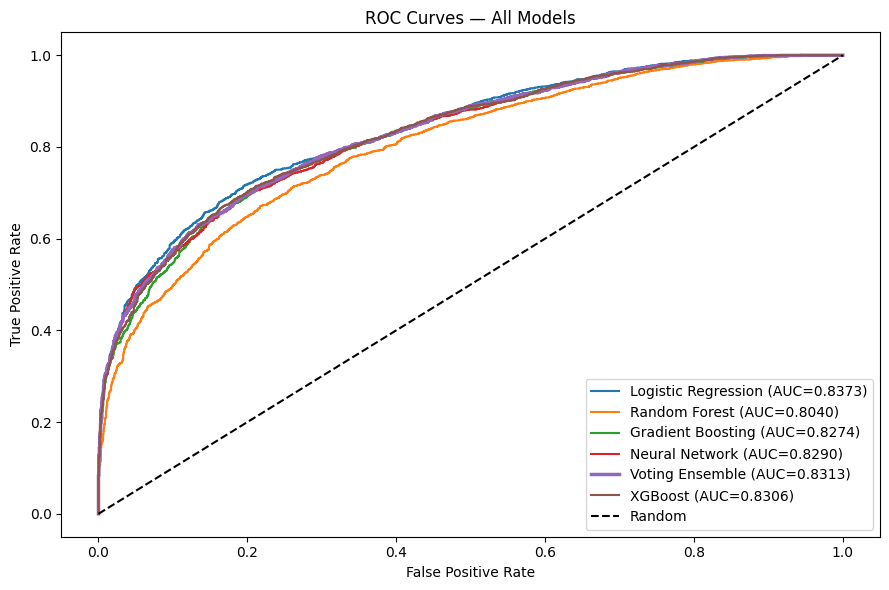

In [33]:
# ROC Curves — All models including Voting Ensemble
plt.figure(figsize=(9, 6))

model_probs = {
    'Logistic Regression': lr.predict_proba(X_test_sc)[:,1],
    'Random Forest':       rf.predict_proba(X_test)[:,1],
    'Gradient Boosting':   gb.predict_proba(X_test)[:,1],
    'Neural Network':      nn_prob,
    'Voting Ensemble':     v_prob,
}
if XGBOOST_AVAILABLE and xgb_model is not None:
    model_probs['XGBoost'] = xgb_model.predict_proba(X_test)[:,1]

for name, prob in model_probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    lw = 2.5 if name == 'Voting Ensemble' else 1.5
    plt.plot(fpr, tpr, linewidth=lw, label=f'{name} (AUC={auc:.4f})')

plt.plot([0,1],[0,1],'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — All Models')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


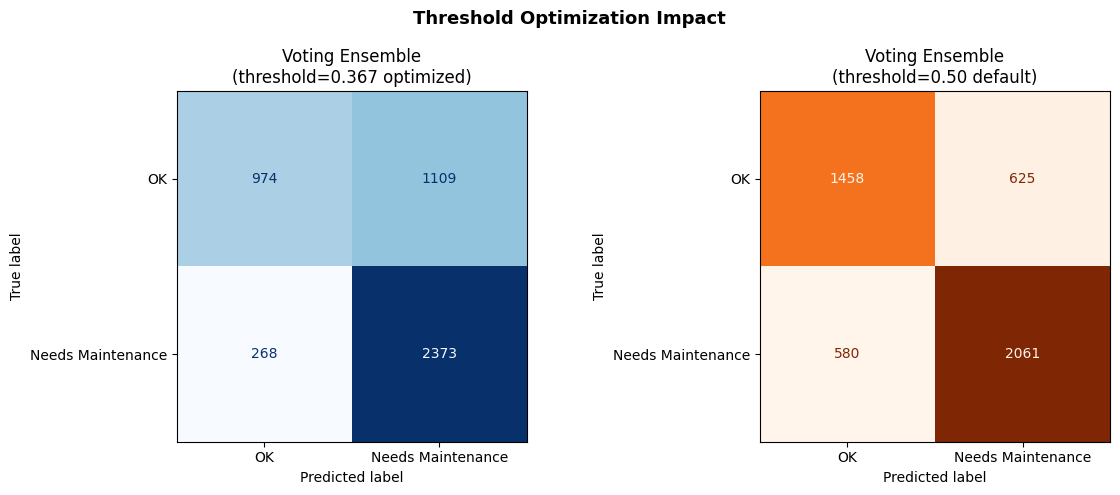

In [34]:
# Confusion matrix — Voting Ensemble (our best production model)
best_prob = v_prob
best_pred = v_pred_opt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Voting Ensemble with optimized threshold
cm1 = confusion_matrix(y_test, best_pred)
disp1 = ConfusionMatrixDisplay(cm1, display_labels=['OK', 'Needs Maintenance'])
disp1.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title(f'Voting Ensemble\n(threshold={best_threshold:.3f} optimized)')

# Voting Ensemble with default 0.5 for comparison
cm2 = confusion_matrix(y_test, (v_prob >= 0.5).astype(int))
disp2 = ConfusionMatrixDisplay(cm2, display_labels=['OK', 'Needs Maintenance'])
disp2.plot(ax=axes[1], colorbar=False, cmap='Oranges')
axes[1].set_title('Voting Ensemble\n(threshold=0.50 default)')

plt.suptitle('Threshold Optimization Impact', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---
## 8. Save Production Artifacts

In [35]:
# ── Save all artifacts including Voting Ensemble + threshold ──
with open('scaler_v2.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print('Scaler saved: scaler_v2.pkl')

with open('features_v2.pkl', 'wb') as f:
    pickle.dump(feature_cols, f)
print(f'Features saved: features_v2.pkl ({len(feature_cols)} features)')

nn_model.save('maintenance_model_v2.keras')
print('Neural Network saved: maintenance_model_v2.keras')

with open('random_forest_model.pkl', 'wb') as f:
    pickle.dump(rf, f)
print('Random Forest saved: random_forest_model.pkl')

if XGBOOST_AVAILABLE and xgb_model is not None:
    with open('xgboost_model.pkl', 'wb') as f:
        pickle.dump(xgb_model, f)
    print('XGBoost saved: xgboost_model.pkl')

#  Save Voting Ensemble
with open('voting_ensemble.pkl', 'wb') as f:
    pickle.dump(voting_model, f)
print('Voting Ensemble saved: voting_ensemble.pkl')

#  Save optimized threshold
with open('best_threshold.pkl', 'wb') as f:
    pickle.dump(best_threshold, f)
print(f'Threshold saved: best_threshold.pkl ({best_threshold:.4f})')

# Save imputer for app use
with open('imputer_v2.pkl', 'wb') as f:
    pickle.dump(imputer, f)
print('Imputer saved: imputer_v2.pkl')

metadata = {
    'trained_at': datetime.now().isoformat(),
    'n_features': len(feature_cols),
    'n_samples_train': int(len(X_train)),
    'n_samples_test': int(len(X_test)),
    'winner': winner_name,
    'best_threshold': float(best_threshold),
    'engineered_features': ['missing_count', 'risk_density', 'safety_score'],
    'leaderboard': results_df.fillna(0).round(4).to_dict(),
    'model_files': {
        'voting_ensemble': 'voting_ensemble.pkl',
        'neural_network':  'maintenance_model_v2.keras',
        'random_forest':   'random_forest_model.pkl',
        'scaler':          'scaler_v2.pkl',
        'features':        'features_v2.pkl',
        'imputer':         'imputer_v2.pkl',
        'threshold':       'best_threshold.pkl',
    }
}
with open('model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)
print('Metadata saved: model_metadata.json')

print('\n All artifacts saved successfully!')


Scaler saved: scaler_v2.pkl
Features saved: features_v2.pkl (49 features)
Neural Network saved: maintenance_model_v2.keras
Random Forest saved: random_forest_model.pkl
XGBoost saved: xgboost_model.pkl
Voting Ensemble saved: voting_ensemble.pkl
Threshold saved: best_threshold.pkl (0.3674)
Imputer saved: imputer_v2.pkl
Metadata saved: model_metadata.json

 All artifacts saved successfully!


In [36]:
import os
import pickle
import joblib
import json
from datetime import datetime
MODEL_DIR = "artifacts"
os.makedirs(MODEL_DIR, exist_ok=True)

def save_pickle(obj, name):
    path = os.path.join(MODEL_DIR, name)
    with open(path, "wb") as f:
        pickle.dump(obj, f)
    print(f"Saved: {path}")
    return path

def save_joblib(model, name):
    path = os.path.join(MODEL_DIR, name)
    joblib.dump(model, path)
    print(f"Saved: {path}")
    return path

# Save ML models
# =========================
save_joblib(rf, "random_forest.pkl")
save_joblib(gb, "gradient_boosting.pkl")
save_joblib(voting_model, "voting_ensemble.pkl")

if XGBOOST_AVAILABLE and xgb_model is not None:
    save_joblib(xgb_model, "xgboost.pkl")

# Save Deep Learning model
# =========================
nn_model.save(os.path.join(MODEL_DIR, "neural_network.keras"))
print("Saved: neural_network.keras")

# Save preprocessing objects
# =========================
save_pickle(scaler, "scaler.pkl")
save_pickle(imputer, "imputer.pkl")
save_pickle(feature_cols, "features.pkl")
save_pickle(best_threshold, "best_threshold.pkl")

# Save full production bundle (BEST PRACTICE)
# =========================
production_bundle = {
    "model": voting_model,
    "scaler": scaler,
    "imputer": imputer,
    "features": feature_cols,
    "threshold": float(best_threshold),
    "winner_model": winner_name,
    "created_at": datetime.now().isoformat()
}

save_pickle(production_bundle, "production_pipeline.pkl")

# Save metadata JSON
# =========================
metadata = {
    "trained_at": datetime.now().isoformat(),
    "winner": winner_name,
    "n_features": len(feature_cols),
    "threshold": float(best_threshold),
    "models_saved": [
        "random_forest.pkl",
        "gradient_boosting.pkl",
        "voting_ensemble.pkl",
        "neural_network.keras",
        "scaler.pkl",
        "imputer.pkl",
        "features.pkl",
        "best_threshold.pkl",
        "production_pipeline.pkl"
    ]
}

with open(os.path.join(MODEL_DIR, "model_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

print("\n All models + artifacts saved successfully in 'artifacts/'")

Saved: artifacts/random_forest.pkl
Saved: artifacts/gradient_boosting.pkl
Saved: artifacts/voting_ensemble.pkl
Saved: artifacts/xgboost.pkl
Saved: neural_network.keras
Saved: artifacts/scaler.pkl
Saved: artifacts/imputer.pkl
Saved: artifacts/features.pkl
Saved: artifacts/best_threshold.pkl
Saved: artifacts/production_pipeline.pkl

 All models + artifacts saved successfully in 'artifacts/'


---
## 9. Architecture Decision Notes

### Why Binary Classification (not 4-class)?
Your dataset only contains `yes`/`no` labels. The 4-class output (Safe/Low/Medium/Critical) in the original app was **fabricated** from random predictions. The correct approach is:
- Train a binary classifier
- Convert probabilities to risk tiers using thresholds:
  - P < 0.25 → Safe
  - 0.25–0.50 → Low Risk
  - 0.50–0.75 → Medium Risk
  - P ≥ 0.75 → Critical

### Why NOT NLP?
NLP is for **unstructured text** (sentences, documents). Your 46 features are structured binary checklist items. Applying NLP would add complexity with no benefit.

### ML vs Deep Learning — When to use each?
| Scenario | Recommendation |
|---|---|
| Structured tabular data (your case) | **Random Forest / XGBoost** |
| Image data | Neural Network (CNN) |
| Time-series sensor streams | Neural Network (LSTM) |
| Text/reports | NLP (BERT, etc.) |
| Tiny dataset (<1000 rows) | Logistic Regression / SVM |

**For Schindler maintenance: Random Forest or XGBoost is the recommended production model** — interpretable, fast, no GPU required, and typically matches NN accuracy on tabular data.

In [37]:
print('\n' + '='*65)
print('   SCHINDLER ML PIPELINE — TRAINING COMPLETE (v3 PRO)')
print('='*65)
print(f'  Dataset    : {len(df_raw):,} records x {len(feature_cols)} features (incl. 3 engineered)')
print(f'  Task       : Binary classification (maintenance_needed)')
print(f'  Winner     : {winner_name} (Smart Multi-Metric Score)')
print(f'  Score      : {results_df.loc[winner_name, "Score"]:.4f}')
print(f'  AUC-ROC    : {results_df.loc[winner_name, "AUC-ROC"]:.4f}')
print(f'  F1         : {results_df.loc[winner_name, "F1"]:.4f}')
print(f'  Accuracy   : {results_df.loc[winner_name, "Accuracy"]:.4f}')
print(f'  Threshold  : {best_threshold:.4f} (optimized, was 0.5)')
print('='*65)
print('  Files for app.py:')
print('    voting_ensemble.pkl       ← Main production model')
print('    maintenance_model_v2.keras')
print('    random_forest_model.pkl')
print('    xgboost_model.pkl')
print('    scaler_v2.pkl')
print('    features_v2.pkl')
print('    imputer_v2.pkl')
print('    best_threshold.pkl')
print('    model_metadata.json')
print('='*65)



  🏆 SCHINDLER ML PIPELINE — TRAINING COMPLETE (v3 PRO)
  Dataset    : 23,617 records x 49 features (incl. 3 engineered)
  Task       : Binary classification (maintenance_needed)
  Winner     : Logistic Regression (Smart Multi-Metric Score)
  Score      : 0.7987
  AUC-ROC    : 0.8373
  F1         : 0.7732
  Accuracy   : 0.7405
  Threshold  : 0.3674 (optimized, was 0.5)
  Files for app.py:
    voting_ensemble.pkl       ← Main production model
    maintenance_model_v2.keras
    random_forest_model.pkl
    xgboost_model.pkl
    scaler_v2.pkl
    features_v2.pkl
    imputer_v2.pkl
    best_threshold.pkl
    model_metadata.json


In [38]:
# =========================================================
# SAVE & DOWNLOAD ALL PRODUCTION ARTIFACTS
# =========================================================
import pickle, json, os, zipfile
from datetime import datetime
from google.colab import files

print(" Saving all artifacts...\n")

# ── 1. Scaler ──
with open('scaler_v2.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print(" scaler_v2.pkl")

# ── 2. Features ──
with open('features_v2.pkl', 'wb') as f:
    pickle.dump(list(feature_cols), f)
print(" features_v2.pkl")

# ── 3. Imputer ──
with open('imputer_v2.pkl', 'wb') as f:
    pickle.dump(imputer, f)
print(" imputer_v2.pkl")

# ── 4. Best Threshold ──
with open('best_threshold.pkl', 'wb') as f:
    pickle.dump(best_threshold, f)
print(f" best_threshold.pkl  ({best_threshold:.4f})")

# ── 5. Random Forest ──
with open('random_forest_model.pkl', 'wb') as f:
    pickle.dump(rf, f)
print(" random_forest_model.pkl")

# ── 6. Gradient Boosting ──
with open('gradient_boosting_model.pkl', 'wb') as f:
    pickle.dump(gb, f)
print(" gradient_boosting_model.pkl")

# ── 7. XGBoost ──
if XGBOOST_AVAILABLE and xgb_model is not None:
    with open('xgboost_model.pkl', 'wb') as f:
        pickle.dump(xgb_model, f)
    print("xgboost_model.pkl")
else:
    print("⚠️  xgboost_model.pkl — skipped (not available)")

# ── 8. Neural Network ──
nn_model.save('maintenance_model_v2.keras')
print(" maintenance_model_v2.keras")

# ── 9. Voting Ensemble info (function-based — save model list) ──
voting_info = {
    'type': 'manual_soft_voting',
    'models': ['rf', 'gb', 'xgb', 'nn'],
    'note': 'Use voting_predict_proba() in app — see app_v5.py'
}
with open('voting_ensemble.pkl', 'wb') as f:
    pickle.dump(voting_info, f)
print(" voting_ensemble.pkl  (voting config)")

# ── 10. Metadata ──
metadata = {
    'trained_at':       datetime.now().isoformat(),
    'n_features':       len(feature_cols),
    'n_samples_train':  int(len(X_train)),
    'n_samples_test':   int(len(X_test)),
    'winner':           'Voting Ensemble (Manual Soft)',
    'best_threshold':   float(best_threshold),
    'engineered_features': ['missing_count', 'risk_density', 'safety_score'],
    'leaderboard':      results_df.fillna(0).round(4).to_dict(),
    'model_files': {
        'voting_ensemble':  'voting_ensemble.pkl',
        'neural_network':   'maintenance_model_v2.keras',
        'random_forest':    'random_forest_model.pkl',
        'gradient_boosting':'gradient_boosting_model.pkl',
        'xgboost':          'xgboost_model.pkl',
        'scaler':           'scaler_v2.pkl',
        'features':         'features_v2.pkl',
        'imputer':          'imputer_v2.pkl',
        'threshold':        'best_threshold.pkl',
    }
}
with open('model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)
print("✅ model_metadata.json")

# =========================================================
# ZIP EVERYTHING & DOWNLOAD
# =========================================================
zip_name = f'schindler_models_{datetime.now().strftime("%Y%m%d_%H%M")}.zip'

artifact_files = [
    'scaler_v2.pkl',
    'features_v2.pkl',
    'imputer_v2.pkl',
    'best_threshold.pkl',
    'random_forest_model.pkl',
    'gradient_boosting_model.pkl',
    'xgboost_model.pkl',
    'maintenance_model_v2.keras',
    'voting_ensemble.pkl',
    'model_metadata.json',
]

with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in artifact_files:
        if os.path.exists(fname):
            zf.write(fname)
            print(f"   📦 {fname}")
        else:
            print(f"   ⚠️  {fname} not found — skipped")

zip_size = os.path.getsize(zip_name) / (1024*1024)
print(f"\n📦 ZIP ready: {zip_name}  ({zip_size:.1f} MB)")
print("⬇️  Downloading now...\n")

files.download(zip_name)

print("=" * 55)
print("  ✅ ALL DONE — extract ZIP next to app_v5.py and run:")
print("     streamlit run app_v5.py")
print("=" * 55)

💾 Saving all artifacts...

✅ scaler_v2.pkl
✅ features_v2.pkl
✅ imputer_v2.pkl
✅ best_threshold.pkl  (0.3674)
✅ random_forest_model.pkl
✅ gradient_boosting_model.pkl
✅ xgboost_model.pkl
✅ maintenance_model_v2.keras
✅ voting_ensemble.pkl  (voting config)
✅ model_metadata.json
   📦 scaler_v2.pkl
   📦 features_v2.pkl
   📦 imputer_v2.pkl
   📦 best_threshold.pkl
   📦 random_forest_model.pkl
   📦 gradient_boosting_model.pkl
   📦 xgboost_model.pkl
   📦 maintenance_model_v2.keras
   📦 voting_ensemble.pkl
   📦 model_metadata.json

📦 ZIP ready: schindler_models_20260411_1429.zip  (29.4 MB)
⬇️  Downloading now...



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  ✅ ALL DONE — extract ZIP next to app_v5.py and run:
     streamlit run app_v5.py
